# RQ06 — características associadas às métricas DORA

Sprint 3, parte B. Três fatores ligados à H6 × seis medidas, incluindo as variantes obrigatórias: 18 testes em uma única família de Holm. Os cálculos são reexecutados abaixo e comparados aos CSVs publicados.

In [1]:
from pathlib import Path
import sys
import json
from io import StringIO, BytesIO
import pandas as pd
from IPython.display import display, Image
import matplotlib.pyplot as plt

base = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "analises").is_dir())
if str(base) not in sys.path:
    sys.path.insert(0, str(base))
from analises.comum import carregar_dataset, sha256
from analises import rq05, rq06
from analises.artefatos import dispersao, efeitos

df, origem = carregar_dataset(base / "data/dataset.csv")
referencia = base / "results/s03_b"
manifesto = json.loads((referencia / "manifesto.json").read_text(encoding="utf-8"))
assert origem == manifesto["origens"]
parametros = manifesto["parametros"]
print(f"Amostra: {len(df)} projetos; semente: {parametros['semente']}")

def conferir(nome, tabela):
    arquivo = referencia / f"{nome}.csv"
    assert sha256(arquivo) == manifesto["artefatos_sha256"][arquivo.name]
    calculada = pd.read_csv(StringIO(tabela.to_csv(index=False, float_format="%.17g")))
    publicada = pd.read_csv(arquivo)
    pd.testing.assert_frame_equal(calculada, publicada, check_dtype=False, rtol=1e-12, atol=1e-14)


def mostrar_figura(figura):
    buffer = BytesIO()
    figura.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figura)


Amostra: 300 projetos; semente: 42


## Grupos e testes

Tipo: quatro categorias originais. Contribuidores: quartis na população completa, preservando empates no mesmo intervalo. Linguagens com menos de dez projetos formam Outras. Não refazemos grupos depois das exclusões por métrica.

Kruskal–Wallis para três ou mais grupos, com ε² = H/(n−1); Mann–Whitney bilateral para dois, com δ = 2U/(n₁n₂)−1. Um grupo com menos de cinco observações impede o teste daquela combinação; descritivas e motivo continuam disponíveis. Não há testes post-hoc: um teste global significativo não identifica quais pares diferem.

In [2]:
resultado = rq06.analisar(df)
for nome in ("rq06_testes", "rq06_descritivas", "rq06_grupos"):
    conferir(nome, resultado[nome])
assert resultado["grupos_definicao"] == json.loads((referencia / "grupos_definicao.json").read_text(encoding="utf-8"))
display(resultado["grupos_definicao"])
display(resultado["rq06_testes"])

{'contribuidores_limites': [1.0, 23.0, 55.5, 125.5, 1963.0],
 'quartis_metodo': 'quantis lineares; intervalos fechados à direita, primeiro inclui mínimo; limites repetidos removidos',
 'linguagens_minimo': 10,
 'linguagens_agrupadas': ['C',
  'Clojure',
  'Cuda',
  'Dart',
  'Elixir',
  'Emacs Lisp',
  'Gherkin',
  'HTML',
  'Jinja',
  'Jupyter Notebook',
  'Kotlin',
  'OCaml',
  'Objective-C',
  'PHP',
  'PowerShell',
  'Ruby',
  'Scala',
  'Shell',
  'Svelte',
  'Swift',
  'TeX',
  'VHDL',
  'Vala',
  'YAML'],
 'tipos_ordem': ['biblioteca/framework',
  'aplicação/serviço',
  'ferramenta CLI',
  'outro'],
 'grupos_definidos_sobre': 'amostra completa antes de excluir métricas ausentes'}

,fator,metrica,n_total,n,n_excluidos,grupos_n,ordem_grupos,teste,estatistica,p,efeito,tipo_efeito,interpretacao_efeito,status,p_holm,p_holm_familia_n,significativo_holm
0,tipo_projeto,deployment_frequency,300,300,0,4,biblioteca/framework | aplicação/serviço | fer...,Kruskal-Wallis,6.565791,8.710366e-02,0.021959,epsilon_quadrado,sem_cortes_convencionados,ok,8.710366e-01,18,False
1,tipo_projeto,lead_time_a_horas,300,300,0,4,biblioteca/framework | aplicação/serviço | fer...,Kruskal-Wallis,5.135828,1.621171e-01,0.017177,epsilon_quadrado,sem_cortes_convencionados,ok,1.000000e+00,18,False
2,tipo_projeto,lead_time_b_horas,300,300,0,4,biblioteca/framework | aplicação/serviço | fer...,Kruskal-Wallis,4.062128,2.548331e-01,0.013586,epsilon_quadrado,sem_cortes_convencionados,ok,1.000000e+00,18,False
3,tipo_projeto,cfr_a,300,300,0,4,biblioteca/framework | aplicação/serviço | fer...,Kruskal-Wallis,7.179740,6.638425e-02,0.024013,epsilon_quadrado,sem_cortes_convencionados,ok,7.302267e-01,18,False
4,tipo_projeto,cfr_b,300,289,11,4,biblioteca/framework | aplicação/serviço | fer...,Kruskal-Wallis,4.775257,1.890133e-01,0.016581,epsilon_quadrado,sem_cortes_convencionados,ok,1.000000e+00,18,False
5,tipo_projeto,tempo_recuperacao_horas,300,278,22,4,biblioteca/framework | aplicação/serviço | fer...,Kruskal-Wallis,14.180657,2.669281e-03,0.051194,epsilon_quadrado,sem_cortes_convencionados,ok,3.470066e-02,18,True
6,contribuidores_quartil,deployment_frequency,300,300,0,4,Q1 | Q2 | Q3 | Q4,Kruskal-Wallis,4.511964,2.112256e-01,0.015090,epsilon_quadrado,sem_cortes_convencionados,ok,1.000000e+00,18,False
7,contribuidores_quartil,lead_time_a_horas,300,300,0,4,Q1 | Q2 | Q3 | Q4,Kruskal-Wallis,36.928737,4.763926e-08,0.123507,epsilon_quadrado,sem_cortes_convencionados,ok,8.098674e-07,18,True
8,contribuidores_quartil,lead_time_b_horas,300,300,0,4,Q1 | Q2 | Q3 | Q4,Kruskal-Wallis,47.047829,3.395132e-10,0.157351,epsilon_quadrado,sem_cortes_convencionados,ok,6.111238e-09,18,True
9,contribuidores_quartil,cfr_a,300,300,0,4,Q1 | Q2 | Q3 | Q4,Kruskal-Wallis,1.451229,6.935715e-01,0.004854,epsilon_quadrado,sem_cortes_convencionados,ok,1.000000e+00,18,False


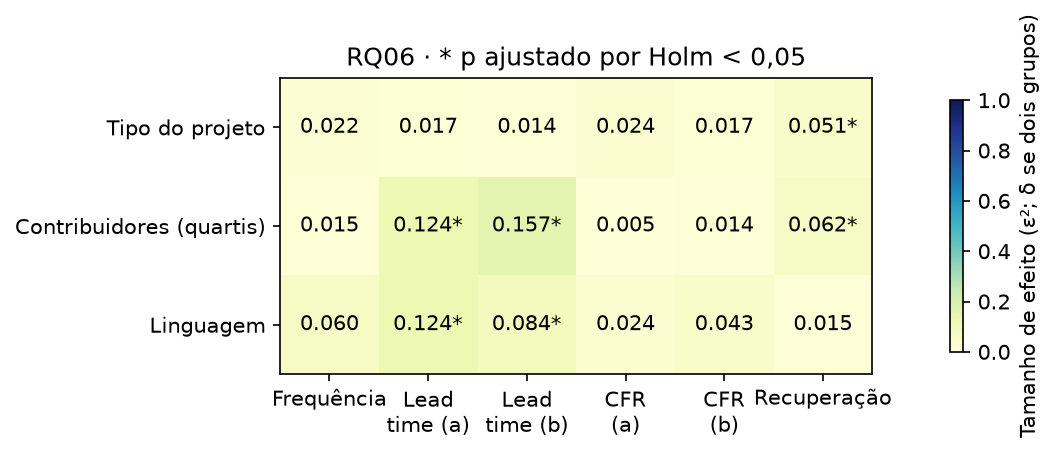

,fator,grupo,metrica,unidade,n_total,n_ausentes,n,mediana,q1,q3,iqr
0,tipo_projeto,biblioteca/framework,deployment_frequency,releases/semana,157,0,157,0.287671,0.153425,0.632877,0.479452
1,tipo_projeto,aplicação/serviço,deployment_frequency,releases/semana,102,0,102,0.421918,0.196575,1.030822,0.834247
2,tipo_projeto,ferramenta CLI,deployment_frequency,releases/semana,32,0,32,0.364384,0.172603,0.815068,0.642466
3,tipo_projeto,outro,deployment_frequency,releases/semana,9,0,9,0.249315,0.172603,0.479452,0.306849
4,tipo_projeto,biblioteca/framework,lead_time_a_horas,horas,157,0,157,275.659167,64.540417,860.421806,795.881389
...,...,...,...,...,...,...,...,...,...,...,...
97,linguagem_grupo,JavaScript,tempo_recuperacao_horas,horas,14,1,13,12.919722,1.428889,23.643611,22.214722
98,linguagem_grupo,Outras,tempo_recuperacao_horas,horas,67,8,59,4.753889,0.913194,32.286319,31.373125
99,linguagem_grupo,Python,tempo_recuperacao_horas,horas,56,3,53,3.805556,0.637083,16.308750,15.671667
100,linguagem_grupo,Rust,tempo_recuperacao_horas,horas,31,1,30,1.872569,0.471771,13.355347,12.883576


,analise,fator,metrica,full_name,campo,motivo
0,RQ06,tipo_projeto,cfr_b,Mithril-mine/libmdbx,cfr_b,evidencia_textual_insuficiente
1,RQ06,tipo_projeto,cfr_b,Monica-Pass/Monica,cfr_b,evidencia_textual_insuficiente
2,RQ06,tipo_projeto,cfr_b,Yazelix/nova,cfr_b,evidencia_textual_insuficiente
3,RQ06,tipo_projeto,cfr_b,YumeYucca/YumeBox,cfr_b,evidencia_textual_insuficiente
4,RQ06,tipo_projeto,cfr_b,caezium/burrow,cfr_b,evidencia_textual_insuficiente
...,...,...,...,...,...,...
94,RQ06,linguagem_grupo,tempo_recuperacao_horas,react-component/field-form,tempo_recuperacao_horas,sem_episodios
95,RQ06,linguagem_grupo,tempo_recuperacao_horas,react-component/tree,tempo_recuperacao_horas,sem_episodios
96,RQ06,linguagem_grupo,tempo_recuperacao_horas,s2b-dev/smart-second-brain,tempo_recuperacao_horas,sem_episodios
97,RQ06,linguagem_grupo,tempo_recuperacao_horas,spike0en/nothing_archive,tempo_recuperacao_horas,sem_episodios


In [3]:
mostrar_figura(efeitos(resultado["rq06_testes"]))
display(resultado["rq06_descritivas"])
display(resultado["exclusoes"])

## Interpretação

Seis comparações permanecem significativas: recuperação por tipo; os dois lead times e recuperação por contribuidores; os dois lead times por linguagem. Não há evidência ajustada de diferença em frequência ou CFR por esses fatores.

H6 recebe apoio apenas parcial: a linguagem também se associa ao lead time e comunidades maiores apresentam medianas de lead time superiores à expectativa de entrega mais rápida. Medianas descrevem os grupos; não substituem testes post-hoc nem autorizam conclusões causais.

Os 22 projetos sem episódios de recuperação observados não recebem tempo zero. A categoria outro tem apenas seis recuperações disponíveis. Há 60 tipos oriundos de consenso triplo e 240 de revisão individual após sugestões automáticas; a diferença de proveniência permanece uma ameaça. Grupos possuem tamanhos e composições diferentes: não se interpreta o tamanho de efeito como ranking causal dos fatores.